In [1]:
import os
import glob
import pandas as pd

MANIFEST = glob.glob("/kaggle/input/**/DR_all.csv", recursive=True)[0]
print("Manifest found at:", MANIFEST)

df = pd.read_csv(MANIFEST)

print("Rows:", len(df))
print("\nImages per split:\n", df["split"].value_counts())
print("\nFirst image path exists:", os.path.exists(df["path"].iloc[0]))
df.head()

Manifest found at: /kaggle/input/datasets/kabirsinghsachdeva/manifest-2/DR_all.csv
Rows: 88839

Images per split:
 split
unused    45578
train     30287
test       6491
val        6483
Name: count, dtype: int64

First image path exists: True


,filename,path,source,group_id,grade,label,orig_split,split,excluded_reason
0,005b95c28852.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_005b95c28852,0,0,train,unused,trimmed_to_match_ratio
1,0097f532ac9f.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_0097f532ac9f,0,0,train,train,NaN
2,00cc2b75cddd.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_00cc2b75cddd,0,0,train,train,NaN
3,00f6c1be5a33.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_00f6c1be5a33,0,0,train,unused,trimmed_to_match_ratio
4,0125fbd2e791.jpg,/kaggle/input/datasets/ascanipek/eyepacs-aptos...,APTOS,aptos_0125fbd2e791,0,0,train,train,NaN


In [2]:
from PIL import Image
from collections import Counter

sample = df.groupby("source").sample(100, random_state=0)
sizes = Counter()
modes = Counter()

for _, row in sample.iterrows():
    img = Image.open(row["path"])
    sizes[(row["source"], img.size)] += 1
    modes[(row["source"], img.mode)] += 1

print("Most common sizes (source, (width, height)): count")
for k, v in sizes.most_common(15):
    print("  ", k, v)
print("\nDifferent sizes found:", len(sizes))
print("\nColour modes:", dict(modes))

Most common sizes (source, (width, height)): count
   ('APTOS', (1050, 1050)) 26
   ('APTOS', (2416, 1736)) 20
   ('APTOS', (2588, 1958)) 19
   ('APTOS', (2048, 1536)) 10
   ('EyePACS', (1024, 1019)) 7
   ('EyePACS', (1024, 1022)) 7
   ('APTOS', (819, 614)) 6
   ('EyePACS', (1024, 1017)) 6
   ('EyePACS', (1023, 1024)) 6
   ('APTOS', (3216, 2136)) 5
   ('EyePACS', (1024, 1023)) 5
   ('APTOS', (2896, 1944)) 4
   ('EyePACS', (1024, 1018)) 4
   ('APTOS', (4288, 2848)) 3
   ('EyePACS', (1024, 981)) 3

Different sizes found: 66

Colour modes: {('APTOS', 'RGB'): 100, ('EyePACS', 'RGB'): 100}


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 512        # change to 384 if storage becomes a problem
BLACK_THRESH = 10     # pixels darker than this count as black background
MIN_FRACTION = 0.01   # a row/column needs >1% retina pixels to count as retina


def load_rgb(path):
    """Open an image and convert it to RGB. Returns None if it can't be read."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        return None
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def crop_black_borders(img):
    """Cut off the black area around the retina. Skips cropping if it looks unsafe."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > BLACK_THRESH
    h, w = mask.shape
    rows = np.where(mask.sum(axis=1) > MIN_FRACTION * w)[0]
    cols = np.where(mask.sum(axis=0) > MIN_FRACTION * h)[0]
    if len(rows) == 0 or len(cols) == 0:
        return img                                   # no retina found: leave as is
    cropped = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    if cropped.shape[0] < 0.3 * h or cropped.shape[1] < 0.3 * w:
        return img                                   # crop too aggressive: leave as is
    return cropped


def pad_to_square(img):
    """Add black padding to the shorter side so the image is square (no stretching)."""
    h, w = img.shape[:2]
    side = max(h, w)
    top = (side - h) // 2
    left = (side - w) // 2
    return cv2.copyMakeBorder(img, top, side - h - top, left, side - w - left,
                              cv2.BORDER_CONSTANT, value=(0, 0, 0))


def resize(img, size=IMG_SIZE):
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def preprocess(path, size=IMG_SIZE):
    """Full pipeline: load -> crop -> pad -> resize. Returns None if the image is broken."""
    img = load_rgb(path)
    if img is None:
        return None
    img = crop_black_borders(img)
    img = pad_to_square(img)
    img = resize(img, size)
    return img


def ben_graham(img, sigma=None):
    """Ben Graham lighting correction. NOT saved to disk - applied at training time as an option."""
    if sigma is None:
        sigma = img.shape[0] / 30
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    out = cv2.addWeighted(img, 4, blur, -4, 128)
    retina = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > BLACK_THRESH
    out[~retina] = 0                                 # keep the background black
    return out


def process_one(args):
    """Preprocess one image and save it as JPEG (quality 95). Returns (source_path, success)."""
    src, dst = args
    try:
        img = preprocess(src)
        if img is None:
            return src, False
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        ok = cv2.imwrite(dst, cv2.cvtColor(img, cv2.COLOR_RGB2BGR),
                         [cv2.IMWRITE_JPEG_QUALITY, 95])
        return src, bool(ok)
    except Exception:
        return src, False


# Quick test on one image
test = preprocess(df["path"].iloc[0])
print("Test image shape:", test.shape)

Test image shape: (512, 512, 3)


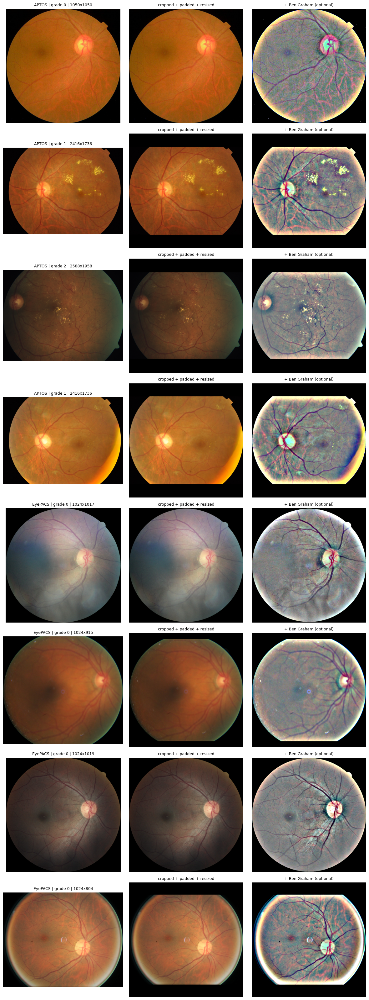

In [4]:
def show_examples(n_per_source=4, seed=0):
    sample = df.groupby("source").sample(n_per_source, random_state=seed)
    fig, axes = plt.subplots(len(sample), 3, figsize=(12, 4 * len(sample)))
    for i, (_, row) in enumerate(sample.iterrows()):
        original = load_rgb(row["path"])
        processed = preprocess(row["path"])

        axes[i, 0].imshow(original)
        axes[i, 0].set_title(
            f"{row['source']} | grade {row['grade']} | {original.shape[1]}x{original.shape[0]}",
            fontsize=9)
        axes[i, 1].imshow(processed)
        axes[i, 1].set_title("cropped + padded + resized", fontsize=9)
        axes[i, 2].imshow(ben_graham(processed))
        axes[i, 2].set_title("+ Ben Graham (optional)", fontsize=9)

        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_examples(n_per_source=4)

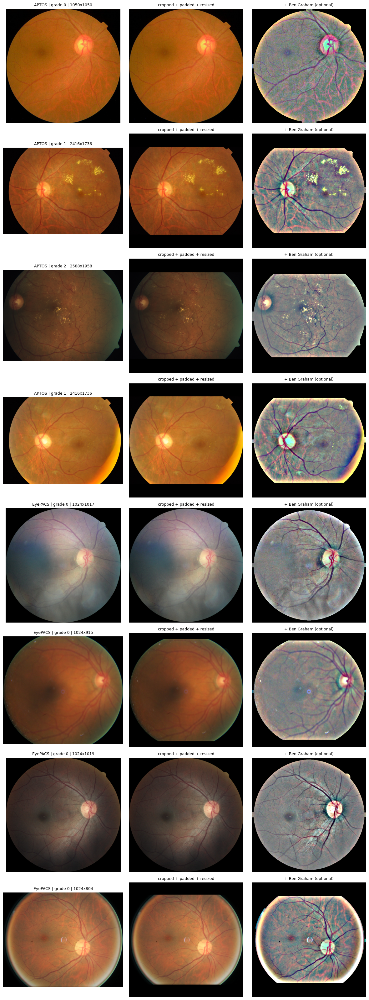

In [5]:
def ben_graham(img, sigma=None, edge_frac=0.03):
    """Ben Graham lighting correction, with the bright edge ring removed."""
    if sigma is None:
        sigma = img.shape[0] / 30
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    out = cv2.addWeighted(img, 4, blur, -4, 128)

    retina = (cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > BLACK_THRESH).astype(np.uint8)
    k = max(3, int(img.shape[0] * edge_frac))
    retina = cv2.erode(retina, np.ones((k, k), np.uint8))   # shrink the mask slightly
    out[retina == 0] = 0                                    # black out the edge + background
    return out

show_examples(n_per_source=4)

In [6]:
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm

TEST_RUN = False          # True = only 200 images. Change to False for the full run.
OUT_DIR = "/kaggle/working/processed"

# Where each processed image will be saved: processed/<split>/<filename>
df["processed_path"] = [
    os.path.join(OUT_DIR, s, f) for s, f in zip(df["split"], df["filename"])
]

todo = df.sample(200, random_state=0) if TEST_RUN else df
jobs = list(zip(todo["path"], todo["processed_path"]))

print(f"Processing {len(jobs)} images using {os.cpu_count()} CPU cores...")
with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
    results = dict(tqdm(ex.map(process_one, jobs, chunksize=32), total=len(jobs)))

df["load_ok"] = df["path"].map(results)
print("Processed:", len(results))
print("Failed:", sum(not v for v in results.values()))

Processing 88839 images using 4 CPU cores...


  0%|          | 0/88839 [00:00<?, ?it/s]

Processed: 88839
Failed: 0


In [7]:
done = df[df["load_ok"] == True]
failed = df[df["load_ok"] == False]

print("Successful:", len(done))
print("Failed:", len(failed))
if len(failed):
    print(failed[["filename", "source", "split"]].head(20))

# Check a few saved files
print("\nSample of saved files:")
for p in done["processed_path"].sample(min(5, len(done)), random_state=0):
    img = cv2.imread(p)
    print("  ", img.shape, os.path.getsize(p) // 1024, "KB", p.replace(OUT_DIR, ""))

# Total disk usage
total_gb = sum(os.path.getsize(p) for p in done["processed_path"]) / 1e9
print(f"\nTotal size on disk: {total_gb:.2f} GB")
if TEST_RUN:
    print(f"Estimated size for all images: {total_gb / len(done) * len(df):.1f} GB")

# Images per split
print("\nProcessed images per split:\n", done["split"].value_counts())

df.to_csv("/kaggle/working/manifest_v2.csv", index=False)
print("\nSaved manifest_v2.csv")

Successful: 88839
Failed: 0

Sample of saved files:
   (512, 512, 3) 47 KB /train/18775_left.jpg
   (512, 512, 3) 61 KB /train/42819_right.jpg
   (512, 512, 3) 42 KB /train/28303_right.jpg
   (512, 512, 3) 54 KB /unused/8720_right.jpg
   (512, 512, 3) 55 KB /train/5378_right.jpg

Total size on disk: 4.55 GB

Processed images per split:
 split
unused    45578
train     30287
test       6491
val        6483
Name: count, dtype: int64

Saved manifest_v2.csv
